# 🧠 BEED EEG Classification using Machine Learning

Classification of EEG signals using classical machine learning
and neural network approaches.

BEED: Bangalore EEG Epilepsy Dataset
Donated on 3/10/2025
The Bangalore EEG Epilepsy Dataset (BEED) is a comprehensive EEG collection for epileptic seizure detection and classification. Recorded at a neurological research centre in Bangalore, India, it features high-fidelity EEG signals captured using the standard 10-20 electrode system at a 256 Hz sampling rate. BEED contains 16,000 segments of 20-second EEG recordings evenly distributed across four categories: Healthy Subjects (0), Generalized Seizures (1), Focal Seizures (2), and Seizure Events (3), where seizure activity occurs with events like eye blinking, nail biting, or staring. Each category includes data from 20 adult subjects (ages 21-55) with equal gender representation. The dataset comprises 16 EEG channels (X1-X16) corresponding to different brain regions, with a binary label (y) indicating seizure presence (1) or absence (0). BEED supports machine learning in seizure detection, epilepsy analysis, and EEG research with its balanced, high-resolution data.

Dataset Characteristics
Tabular, Multivariate

Subject Area
Health and Medicine

Associated Tasks
Classification

Feature Type
Integer

# Instances
8000

# Features
17

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

## 1. Load and Understand the Dataset

In [2]:
df = pd.read_csv("BEED_Data.csv")

In [3]:
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (8000, 17)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,y
0,4,7,18,25,28,27,20,10,-10,-18,-20,-16,13,32,12,10,0
1,87,114,120,106,76,54,28,5,-19,-49,-85,-102,-100,-89,-61,-21,0
2,-131,-133,-140,-131,-123,-108,-58,-51,-70,-77,-76,-76,-73,-57,-40,-14,0
3,68,104,73,34,-12,-26,-38,-36,-67,-88,-25,31,18,-4,6,-29,0
4,-67,-90,-97,-94,-86,-71,-43,-11,23,46,58,50,39,19,-9,-41,0


In [4]:
df["y"].value_counts()

,count
y,
0,2000
1,2000
2,2000
3,2000


In [5]:
print(df["y"].unique())
print(df["y"].value_counts())

[0 1 2 3]
y
0    2000
1    2000
2    2000
3    2000
Name: count, dtype: int64


## 2. Exploratory Data Analysis

In [6]:
# Convert y to numbers
df["y"] = pd.to_numeric(df["y"], errors="coerce")

# Remove the invalid row
df = df.dropna(subset=["y"])

# Convert y from float to integer
df["y"] = df["y"].astype(int)

print(df["y"].value_counts())

y
0    2000
1    2000
2    2000
3    2000
Name: count, dtype: int64


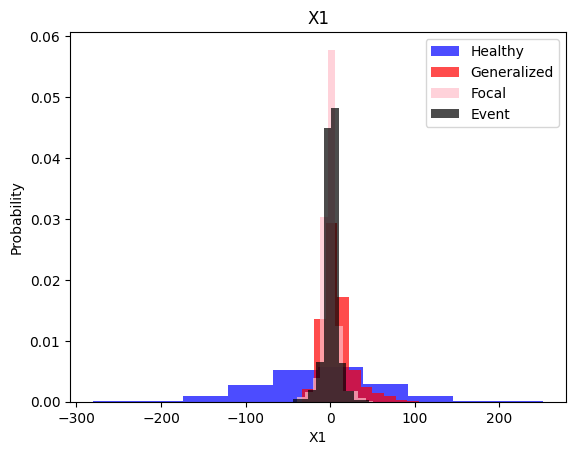

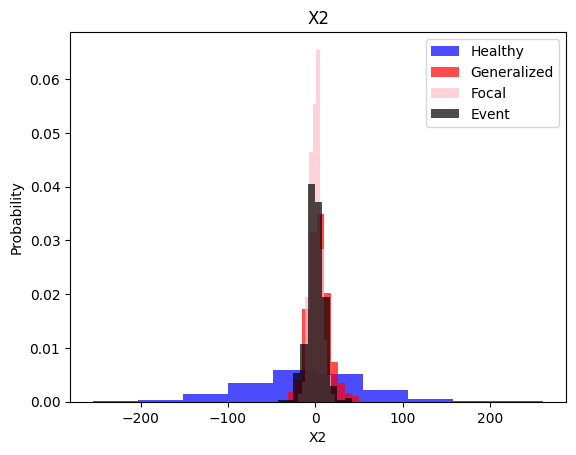

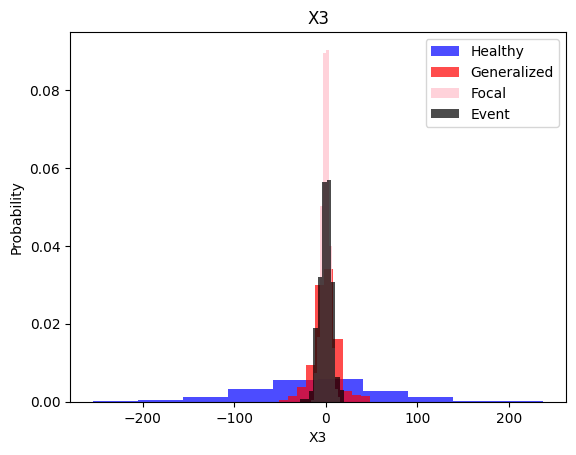

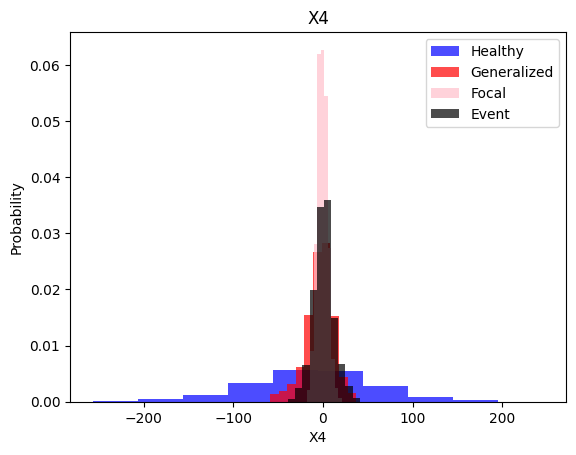

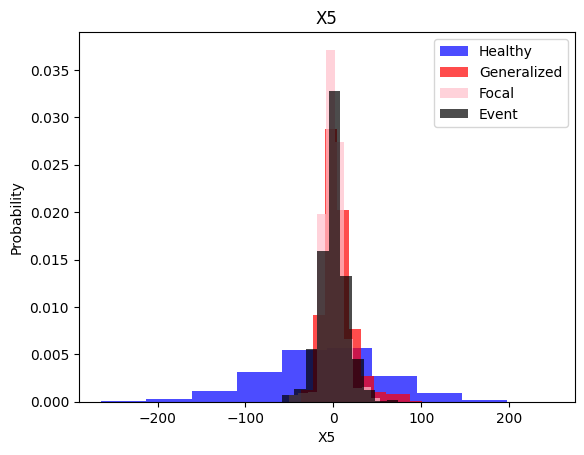

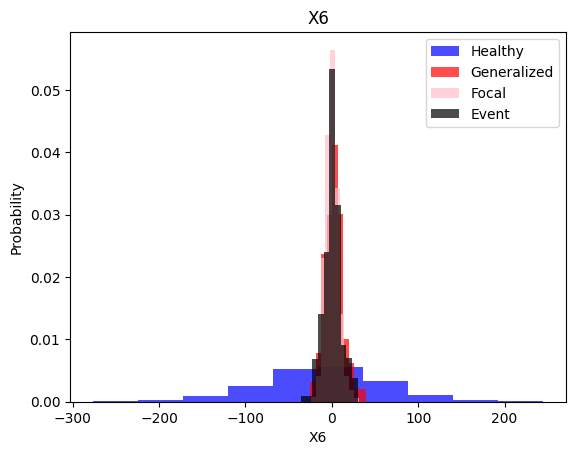

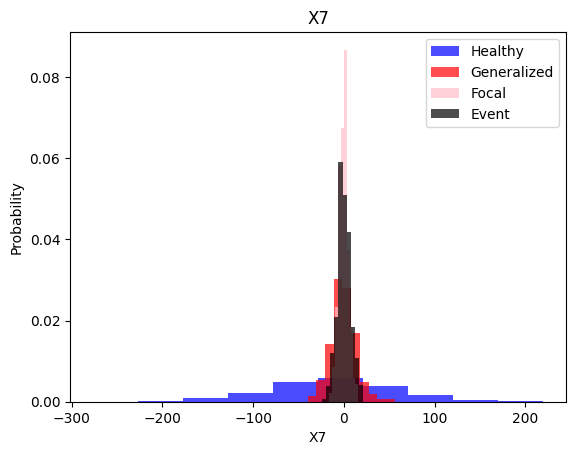

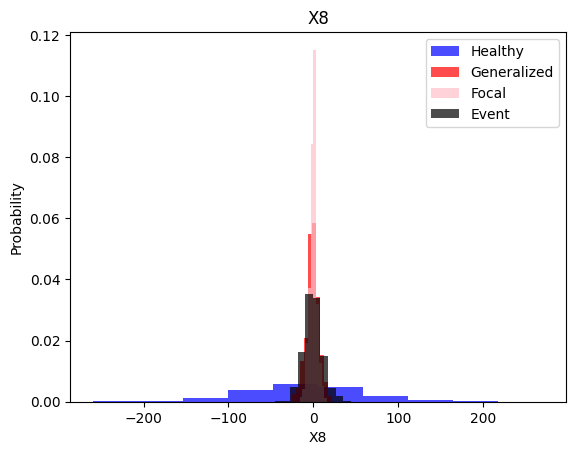

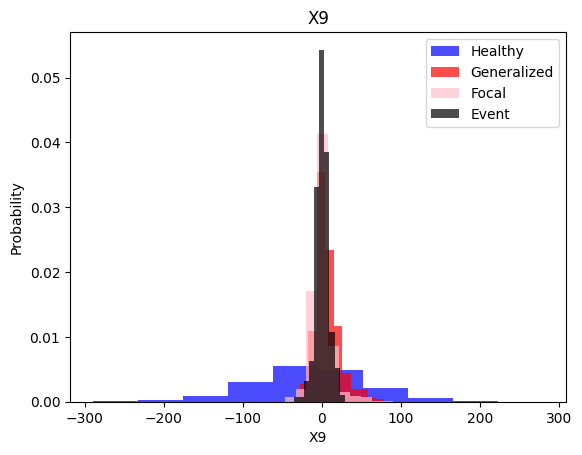

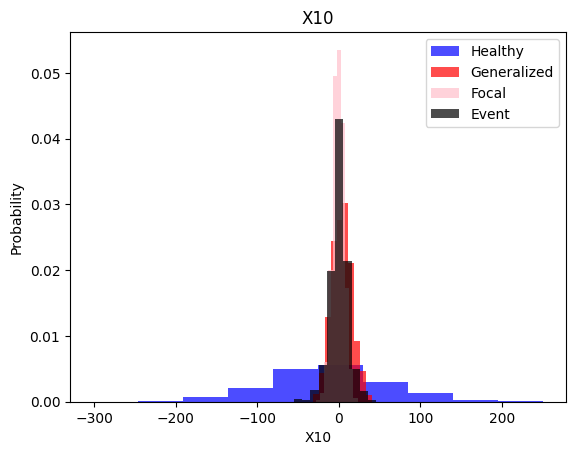

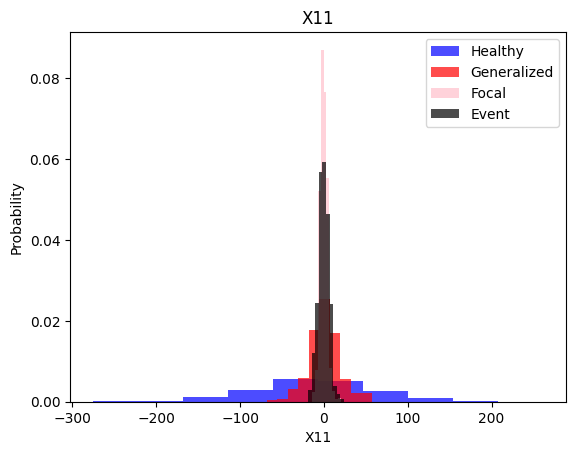

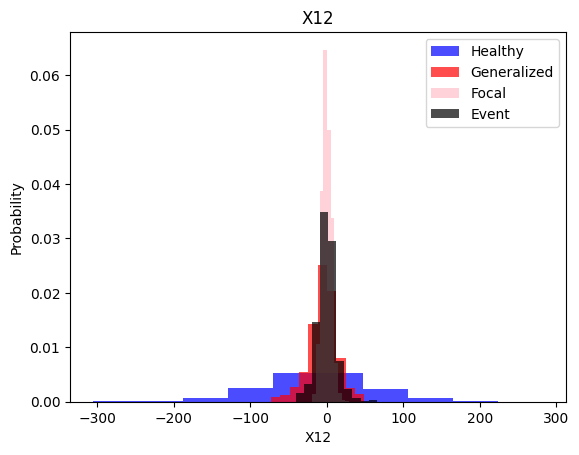

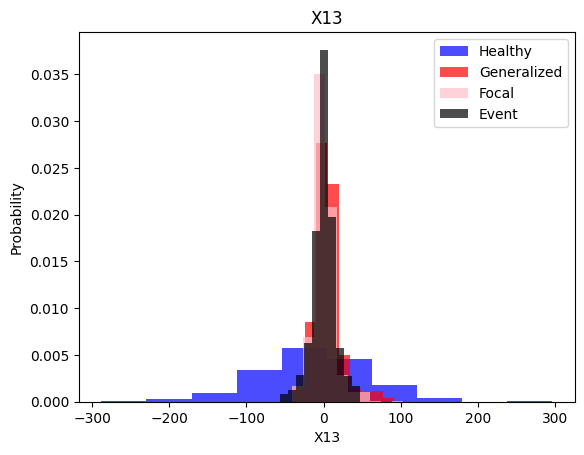

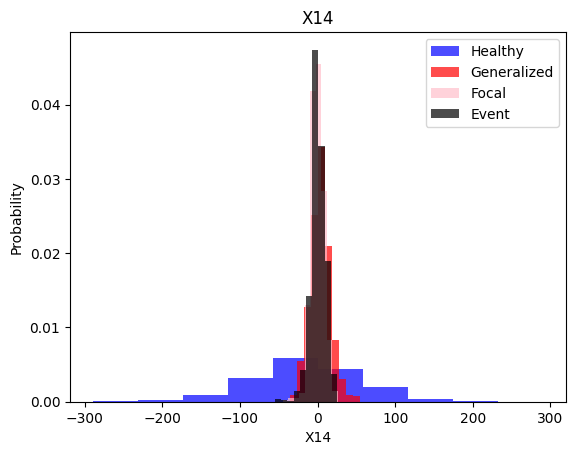

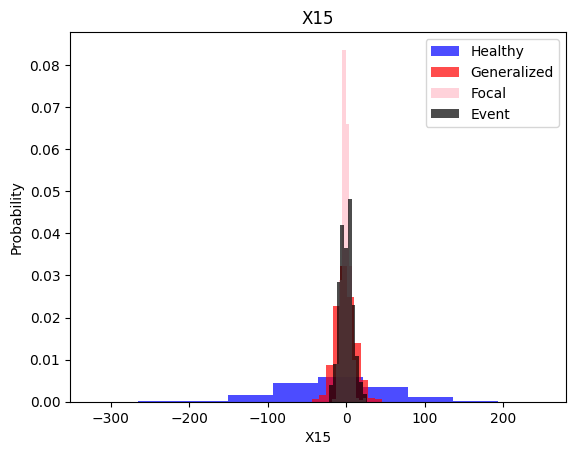

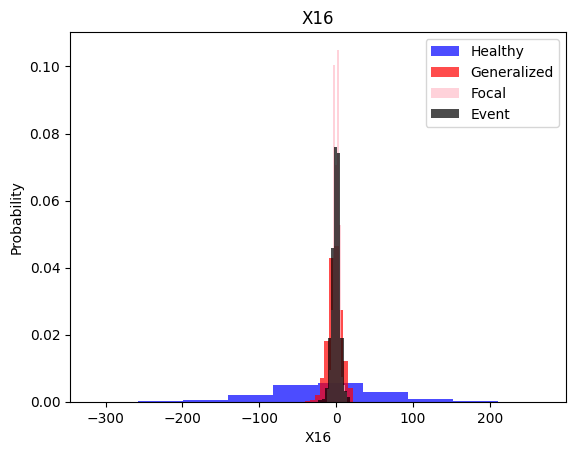

In [7]:
import matplotlib.pyplot as plt

for label in df.columns:
    if label == "y":
        continue

    plt.hist(df[df["y"] == 0][label],
             color="blue",
             label="Healthy",
             alpha=0.7,
             density=True)

    plt.hist(df[df["y"] == 1][label],
             color="red",
             label="Generalized",
             alpha=0.7,
             density=True)

    plt.hist(df[df["y"] == 2][label],
             color="pink",
             label="Focal",
             alpha=0.7,
             density=True)

    plt.hist(df[df["y"] == 3][label],
             color="black",
             label="Event",
             alpha=0.7,
             density=True)

    plt.xlabel(label)
    plt.ylabel("Probability")
    plt.title(label)
    plt.legend()
    plt.show()

In [8]:
train , valid ,test = np.split(df.sample(frac=1),[int(0.6*len(df)),int(0.8*len(df))])

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [9]:
X_train = train.drop(columns=["y"]).values
Y_train = train["y"].values

X_valid = valid.drop(columns=["y"]).values
Y_valid = valid["y"].values

X_test = test.drop(columns=["y"]).values
Y_test = test["y"].values

In [10]:
from sklearn.preprocessing import StandardScaler

In [11]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_valid = scaler.transform(X_valid)

X_test = scaler.transform(X_test)

In [12]:
print(X_train.shape)
print(X_valid.shape)
print(X_test.shape)
print("\n")
print(Y_train.shape)
print(Y_valid.shape)
print(Y_test.shape)

(4800, 16)
(1600, 16)
(1600, 16)


(4800,)
(1600,)
(1600,)


In [13]:
print(X_train[:5])
print(Y_train[:20])

[[ 3.30126204e-01  1.35973798e-01  3.89100410e-01  2.45097892e-01
   1.76990022e-01  3.12239950e-01  7.44489238e-01 -1.07039508e-01
   3.61594851e-01  2.60677994e-01  7.73947100e-01 -3.31029266e-01
   5.53171221e-01  3.50633008e-01  6.11143335e-02  5.72119901e-02]
 [-2.42253825e-02  1.35973798e-01  3.89100410e-01  8.52564678e-01
   3.11170789e-01  1.99507348e-01  6.59290479e-01  1.75681913e-01
   3.61594851e-01  1.50938091e-01  2.54542450e-01  4.80551807e-01
   9.22347581e-01  1.02637036e-01  3.12771869e-01 -2.79847687e-02]
 [ 8.75282490e-01  1.08446416e-01  3.33522080e-01 -2.24308261e-01
   5.25860016e-01  1.99507348e-01  2.04897098e-01  1.75681913e-01
   4.42582919e-01  1.78373067e-01  8.83295448e-01 -3.31029266e-01
   1.57625121e-01  7.91514735e-01  5.36467456e-01 -2.83575045e-01]
 [ 3.02902462e-02 -2.76936934e-01  8.34195986e-02  2.42008785e-02
  -9.13715114e-02  8.67747461e-02 -1.07498351e-01  6.04906041e-03
   9.16346244e-02 -6.85417141e-02 -1.00839679e-01  5.07604509e-01
   7.85

**KNN**

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

In [15]:
knn_model = KNeighborsClassifier()
knn_model.fit(X_train,Y_train)
Y_pred = knn_model.predict(X_valid)
print(classification_report(Y_valid,Y_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99       416
           1       0.97      0.90      0.93       403
           2       0.89      0.93      0.91       400
           3       0.89      0.93      0.91       381

    accuracy                           0.94      1600
   macro avg       0.94      0.93      0.93      1600
weighted avg       0.94      0.94      0.94      1600



# Naive Bayes

In [16]:
from sklearn.naive_bayes import GaussianNB

In [17]:
nb_model = GaussianNB()
nb_model.fit(X_train,Y_train)
Y_pred = nb_model.predict(X_valid)
print(classification_report(Y_valid,Y_pred))

              precision    recall  f1-score   support

           0       0.95      0.95      0.95       416
           1       0.72      0.58      0.64       403
           2       0.65      0.84      0.73       400
           3       0.55      0.49      0.52       381

    accuracy                           0.72      1600
   macro avg       0.72      0.71      0.71      1600
weighted avg       0.72      0.72      0.71      1600



# Support Vactor Machine

In [18]:
from sklearn.svm import SVC

In [19]:
svm_model = SVC()
svm_model.fit(X_train,Y_train)
Y_pred = svm_model.predict(X_valid)
print(classification_report(Y_valid,Y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       416
           1       0.83      0.68      0.75       403
           2       0.56      0.93      0.70       400
           3       0.68      0.35      0.46       381

    accuracy                           0.74      1600
   macro avg       0.77      0.74      0.73      1600
weighted avg       0.77      0.74      0.73      1600



# Logistic Regression

In [20]:
from sklearn.linear_model import LogisticRegression

In [21]:
lr_model = LogisticRegression()
lr_model.fit(X_train,Y_train)
Y_pred = lr_model.predict(X_valid)
print(classification_report(Y_valid,Y_pred))


              precision    recall  f1-score   support

           0       0.78      0.54      0.64       416
           1       0.53      0.59      0.56       403
           2       0.40      0.43      0.41       400
           3       0.37      0.43      0.40       381

    accuracy                           0.50      1600
   macro avg       0.52      0.50      0.50      1600
weighted avg       0.53      0.50      0.50      1600



 # Neural Networks

In [22]:
#Creating a keras model
model = keras.Sequential([
    layers.Input(shape=(16,)),
    layers.Dense(32,activation="relu"),
    layers.Dense(16,activation="relu"),

    layers.Dense(4,activation="softmax")
])

#Compiling the model
model.compile(
    optimizer = "Adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [23]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,140 (4.45 KB)

 Trainable params: 1,140 (4.45 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
history = model.fit(
    X_train,
    Y_train,
    validation_data = (X_valid,Y_valid),
    epochs = 20,
    batch_size = 32
)

Epoch 1/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.4344 - loss: 1.1661 - val_accuracy: 0.5644 - val_loss: 0.9932
Epoch 2/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6046 - loss: 0.8859 - val_accuracy: 0.6269 - val_loss: 0.7764
Epoch 3/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6762 - loss: 0.7081 - val_accuracy: 0.7050 - val_loss: 0.6574
Epoch 4/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7358 - loss: 0.6157 - val_accuracy: 0.7406 - val_loss: 0.5925
Epoch 5/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7510 - loss: 0.5550 - val_accuracy: 0.7806 - val_loss: 0.5353
Epoch 6/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7781 - loss: 0.5055 - val_accuracy: 0.8031 - val_loss: 0.4901
Epoch 7/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8040 - loss: 0.4663 - val_accuracy: 0.8225 - val_loss: 0.4550
Epoch 8/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8208 - loss: 0.4321 - val_accuracy: 0

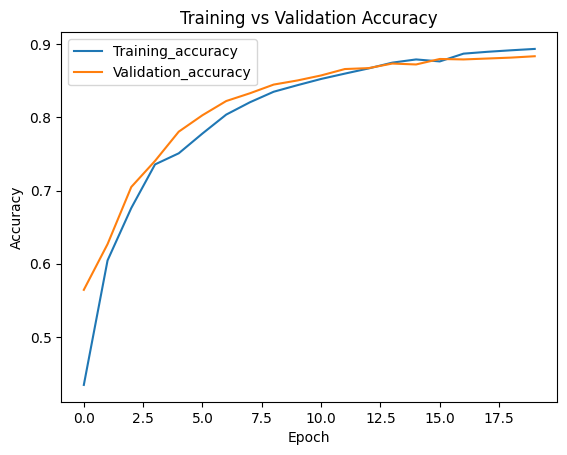

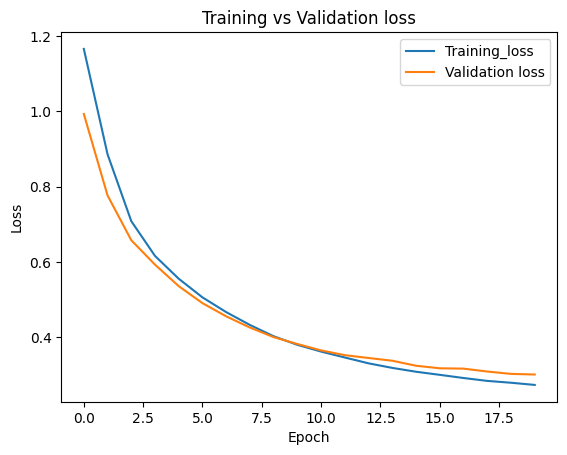

In [25]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"],label = "Training_accuracy")
plt.plot(history.history["val_accuracy"],label = "Validation_accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"],label = "Training_loss")
plt.plot(history.history["val_loss"],label = "Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation loss")
plt.legend()
plt.show()

In [26]:
# Predict probabilities
Y_pred_prob = model.predict(X_valid)

# Convert probabilities to class labels
Y_pred = np.argmax(Y_pred_prob, axis=1)

# Classification report
print(classification_report(Y_valid, Y_pred))

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       416
           1       0.91      0.90      0.91       403
           2       0.83      0.85      0.84       400
           3       0.79      0.78      0.78       381

    accuracy                           0.88      1600
   macro avg       0.88      0.88      0.88      1600
weighted avg       0.88      0.88      0.88      1600



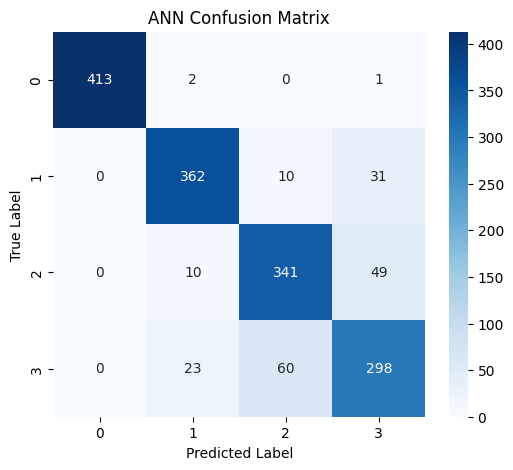

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(Y_valid,Y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot= True,
    fmt="d",
    cmap = "Blues",
    xticklabels=[0,1,2,3],
    yticklabels=[0,1,2,3]

)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ANN Confusion Matrix")
plt.show()

In [28]:
improved_model = keras.Sequential([

    layers.Input(shape=(16,)),
    layers.Dense(32,activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(16,activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(4,activation="softmax")
])


In [29]:
improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [30]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_improved = improved_model.fit(
    X_train,
    Y_train,
    validation_data=(X_valid, Y_valid),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping]
)

Epoch 1/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3767 - loss: 1.2642 - val_accuracy: 0.5700 - val_loss: 1.0721
Epoch 2/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5360 - loss: 1.0593 - val_accuracy: 0.6550 - val_loss: 0.9348
Epoch 3/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5971 - loss: 0.9358 - val_accuracy: 0.6862 - val_loss: 0.8137
Epoch 4/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6367 - loss: 0.8361 - val_accuracy: 0.7113 - val_loss: 0.7184
Epoch 5/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6581 - loss: 0.7570 - val_accuracy: 0.7462 - val_loss: 0.6500
Epoch 6/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6790 - loss: 0.7073 - val_accuracy: 0.7644 - val_loss: 0.5969
Epoch 7/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7013 - loss: 0.6662 - val_accuracy: 0.7744 - val_loss: 0.5603
Epoch 8/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7206 - loss: 0.6262 - val_accuracy: 0.

In [31]:
# Predict using improved ANN
Y_pred_improved_prob = improved_model.predict(X_valid)

# Convert probabilities to class labels
Y_pred_improved = np.argmax(Y_pred_improved_prob, axis=1)

# Classification report
print(classification_report(Y_valid, Y_pred_improved))

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       416
           1       0.93      0.86      0.89       403
           2       0.79      0.86      0.83       400
           3       0.75      0.73      0.74       381

    accuracy                           0.87      1600
   macro avg       0.87      0.86      0.86      1600
weighted avg       0.87      0.87      0.87      1600



# Comparing the Models

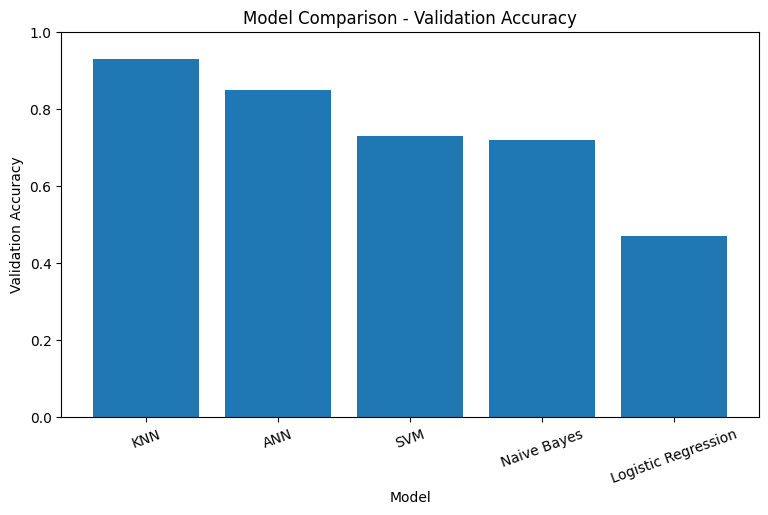

In [32]:
models = [
    "KNN",
    "ANN",
    "SVM",
    "Naive Bayes",
    "Logistic Regression"
]

accuracy = [
    0.93,
    0.85,
    0.73,
    0.72,
    0.47
]

plt.figure(figsize=(9, 5))

plt.bar(models, accuracy)

plt.xlabel("Model")
plt.ylabel("Validation Accuracy")
plt.title("Model Comparison - Validation Accuracy")
plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.show()

FINAL TEST EVALUATION

In [33]:
Y_test_pred = knn_model.predict(X_test)

In [34]:
print(classification_report(Y_test,Y_test_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99       395
           1       0.98      0.90      0.94       398
           2       0.89      0.93      0.91       395
           3       0.90      0.93      0.91       412

    accuracy                           0.94      1600
   macro avg       0.94      0.94      0.94      1600
weighted avg       0.94      0.94      0.94      1600



FINAL CONFUSION MATRIX

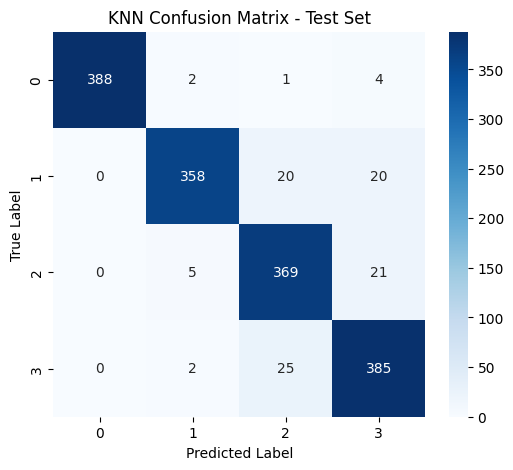

In [35]:
cm_test  = confusion_matrix(Y_test,Y_test_pred)
plt.figure(figsize=(6,5))

sns.heatmap(
    cm_test,
    annot = True,
    fmt="d",
    cmap="Blues",
    xticklabels=[0,1,2,3],
    yticklabels=[0,1,2,3]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("KNN Confusion Matrix - Test Set")

plt.show()

# **CONCLUSION**

In this project, multiple machine learning approaches were evaluated for classification of EEG data from the BEED dataset. KNN achieved the best overall performance among the evaluated models, reaching approximately 93% accuracy and a macro F1-score of 0.93 on the final test set. The ANN models achieved lower performance, demonstrating that a more complex model does not necessarily provide better results for every dataset. The project provided practical experience in preprocessing, model training, evaluation, comparison, and neural network experimentation.